#### Inferencing Model

In [3]:
# Install OpenVINO and Ultralytics
!pip install openvino ultralytics opencv-python

#### Export to OpenVINO Format

In [5]:

from ultralytics import YOLO

# Load your standard PyTorch weight
model = YOLO("best.pt")

# Convert it to the OpenVINO format (Exported with FP16 precision for GPU speed)
model.export(format="openvino", half=True)
print("[SUCCESS] Model successfully converted for your Intel Arc GPU!")

Ultralytics 8.4.55  Python-3.14.0 torch-2.12.0+cpu CPU (Intel Core Ultra 7 258V)
Model summary (fused): 93 layers, 25,841,497 parameters, 0 gradients, 78.7 GFLOPs

PyTorch: starting from 'best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (49.6 MB)

OpenVINO: starting export with openvino 2026.1.0-21367-63e31528c62-releases/2026/1...
OpenVINO: export success  4.3s, saved as 'best_openvino_model\' (49.7 MB)

Export complete (5.6s)
Results saved to E:\Vehicle Detection Task\virtualEnv\Test\best_openvino_model
Predict:         yolo predict task=detect model=best_openvino_model\ imgsz=640 half
Validate:        yolo val task=detect model=best_openvino_model\ imgsz=640 data=/content/drive/MyDrive/Vehicle_Data/DataSet/data.yaml half 
Visualize:       https://netron.app
[SUCCESS] Model successfully converted for your Intel Arc GPU!


#### Initialization on Intel Arc GPU

In [6]:
import cv2
from ultralytics import YOLO

# Path to your OpenVINO exported folder
MODEL_PATH = "best_openvino_model"

# Load the model using the OpenVINO framework
model = YOLO(MODEL_PATH, task="detect")

print("[INFO] Model loaded successfully!")

[INFO] Model loaded successfully!


#### Fast Image Inference on Arc GPU

In [7]:
import matplotlib.pyplot as plt

In [8]:
# This magic command ensures images render directly underneath your notebook cell
%matplotlib inline
print("[INFO] Setup ready for inline rendering!")

[INFO] Setup ready for inline rendering!


[INFO] Running inference on image: testimage4.jpg

image 1/1 e:\Vehicle Detection Task\virtualEnv\Test\testimage4.jpg: 640x640 15 bicycles, 1 car, 18.4ms


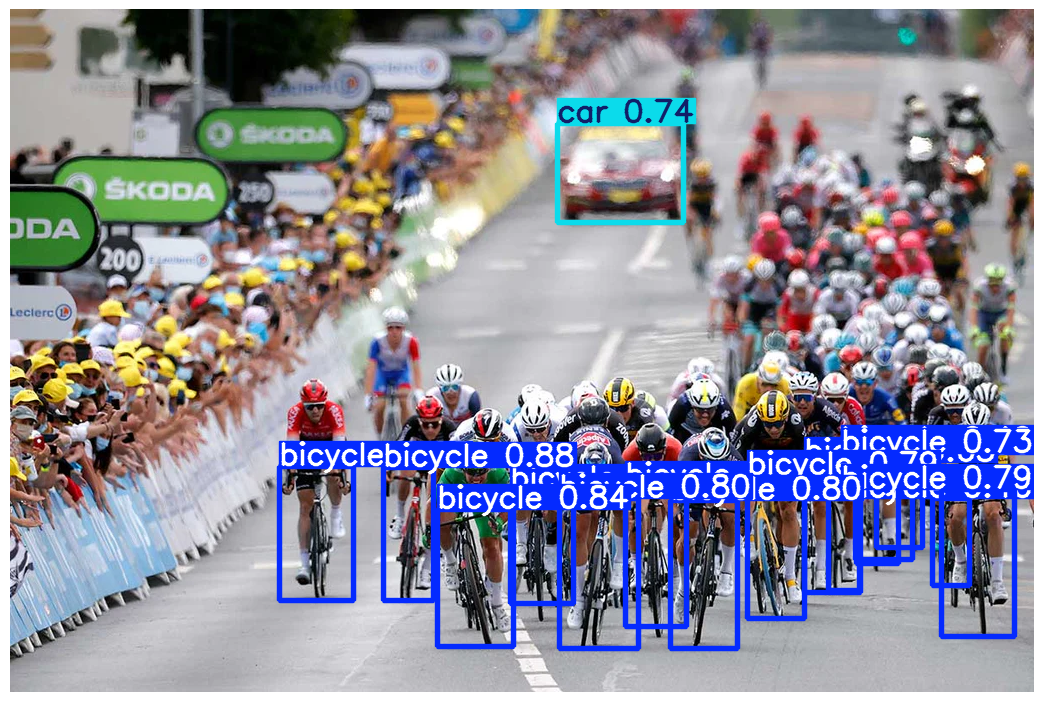

Speed: 4.6ms preprocess, 18.4ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)


In [23]:
IMAGE_PATH = "testimage4.jpg"

print(f"[INFO] Running inference on image: {IMAGE_PATH}")
results = model(IMAGE_PATH, stream=True)

for result in results:
    # 1. Get the annotated array (OpenCV format: BGR)
    annotated_frame = result.plot()
    
    # 2. Convert BGR to RGB so colors display correctly in Matplotlib
    rgb_frame = cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)
    
    # 3. Fetch original dimensions (height, width)
    height, width, _ = rgb_frame.shape
    
    # 4. Configure Matplotlib to match the image's precise original pixel size
    # dpi=100 sets a standard 1-to-1 pixel layout
    fig = plt.figure(figsize=(width / 100, height / 100), dpi=100)
    ax = fig.add_axes([0, 0, 1, 1])
    
    # Hide the axis graph lines and coordinates
    ax.axis('off')
    
    # Display the image directly in the cell output
    ax.imshow(rgb_frame)
    plt.show()

#### High-FPS Video Inference on Arc GPU

In [13]:
VIDEO_PATH = "testvid1.mp4"

print(f"[INFO] OpenVINO running on video: {VIDEO_PATH}")

# 1. Open the video first to read its true dimensions
cap = cv2.VideoCapture(VIDEO_PATH)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release() # Close it immediately; YOLO will handle the loop

# 2. Setup the named window with absolute original sizing
window_name = "YOLOv8 Intel Arc - Video Stream"
cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)
cv2.resizeWindow(window_name, width, height)

# 3. Run the optimized streaming inference
results = model(VIDEO_PATH, stream=True)

for result in results:
    annotated_frame = result.plot()
    
    cv2.imshow(window_name, annotated_frame)
    
    if cv2.waitKey(1) & 0xFF == ord('q'):
        print("[INFO] Video stopped by user.")
        break

cv2.destroyAllWindows()

[INFO] OpenVINO running on video: testvid1.mp4

video 1/1 (frame 1/319) e:\Vehicle Detection Task\virtualEnv\Test\testvid1.mp4: 640x640 30 cars, 20.5ms
video 1/1 (frame 2/319) e:\Vehicle Detection Task\virtualEnv\Test\testvid1.mp4: 640x640 29 cars, 20.7ms
video 1/1 (frame 3/319) e:\Vehicle Detection Task\virtualEnv\Test\testvid1.mp4: 640x640 28 cars, 21.0ms
video 1/1 (frame 4/319) e:\Vehicle Detection Task\virtualEnv\Test\testvid1.mp4: 640x640 24 cars, 20.2ms
video 1/1 (frame 5/319) e:\Vehicle Detection Task\virtualEnv\Test\testvid1.mp4: 640x640 25 cars, 20.0ms
video 1/1 (frame 6/319) e:\Vehicle Detection Task\virtualEnv\Test\testvid1.mp4: 640x640 27 cars, 20.5ms
video 1/1 (frame 7/319) e:\Vehicle Detection Task\virtualEnv\Test\testvid1.mp4: 640x640 28 cars, 21.5ms
video 1/1 (frame 8/319) e:\Vehicle Detection Task\virtualEnv\Test\testvid1.mp4: 640x640 28 cars, 21.0ms
video 1/1 (frame 9/319) e:\Vehicle Detection Task\virtualEnv\Test\testvid1.mp4: 640x640 25 cars, 19.7ms
video 1/1 (frame

#### Real-Time Live Webcam Inference on Arc GPU

In [ ]:
print("[INFO] Starting live webcam inference. Press 'q' to quit.")

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("[ERROR] Could not open webcam.")
else:
    # 1. Force the webcam to grab its native dimension properties
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    
    # 2. Configure the output window to lock onto those dimensions
    window_name = "YOLOv8 Intel Arc - Live Webcam"
    cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)
    cv2.resizeWindow(window_name, width, height)
    
    while cap.isOpened():
        success, frame = cap.read()
        if not success:
            break
        
        results = model(frame)
        annotated_frame = results[0].plot()
        
        cv2.imshow(window_name, annotated_frame)
        
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()
    print("[INFO] Webcam stream closed safely.")